In [58]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [91]:
class Value:
    def __init__(self, data, _children=(), _op='',_label = '' ):
        self.data = data
        self._prev = set(_children)
        self.op = _op
        self._label = _label
        self._grad= 0.0
        self._backward = lambda :None

    def __repr__(self) -> str:
        return f"Value(data={self.data}, label={self._label})"

    def __add__(self, other):
        out = Value(self.data + other.data, (self,other),'+')
        def _backward():
            self._grad += 1.0 * out._grad
            other._grad += 1.0* out._grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        out = Value(self.data * other.data, (self,other),'*')
        def _backward():
            self._grad += 1.0 * out._grad
            other._grad += 1.0 * out._grad
        out._backward = _backward
        return out

    def tanh(self):
        x = self.data
        t = (math.exp(2*x) - 1)/(math.exp(2*x) + 1)
        out = Value(t, (self, ), 'tanh')
        def _backward():
            self._grad+= (1- t**2)*out._grad
        out._backward = _backward
        return out

    def backward(self):
        topo=[]
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for i in v._prev:
                    build_topo(i)
                    topo.append(i)
                topo.append(v)
        build_topo(self)

        self._grad = 1.0
        for node in reversed(topo):
            node._backward()

In [92]:
a = Value(2.0, _label='a')
b = Value(-3.0, _label='b')
c = Value(10.0, _label='c')

In [93]:
e= a*b
e._label='e'

In [94]:
e

Value(data=-6.0, label=e)

In [95]:
d = e + c
d._label = 'd'

In [96]:
d

Value(data=4.0, label=d)

In [97]:
f = Value(-2.0, _label='f')
L = d * f; L._label = 'L'
L

Value(data=-8.0, label=L)

In [98]:
from graphviz import Digraph
def trace(root):
    node, edge = set(), set()
    def build_root(v):
        if v not in node:
            node.add(v)
            for child in v._prev:
                edge.add(child)
                build_root(child)
    build_root(root)
    return node, edge

In [99]:
trace(L)

({Value(data=-2.0, label=f),
  Value(data=-3.0, label=b),
  Value(data=-6.0, label=e),
  Value(data=-8.0, label=L),
  Value(data=10.0, label=c),
  Value(data=2.0, label=a),
  Value(data=4.0, label=d)},
 {Value(data=-2.0, label=f),
  Value(data=-3.0, label=b),
  Value(data=-6.0, label=e),
  Value(data=10.0, label=c),
  Value(data=2.0, label=a),
  Value(data=4.0, label=d)})

In [100]:
def draw_digraph(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}, engine='dot')

    node , edge = trace(root)
    for n in node:
        uid = str(id(n))

        dot.node(name=uid, label = "{ %s | data %.4f | grad %.4f }" % (n._label, n.data, n._grad), shape='record')
        if n.op:
            dot.node(name = uid + n.op, label = n.op)
            dot.edge(uid+n.op, uid)
    for n1, n2 in enumerate(edge):
        dot.edge(str(id(n1)), str(id(n2)) + n2.op)

    return  dot

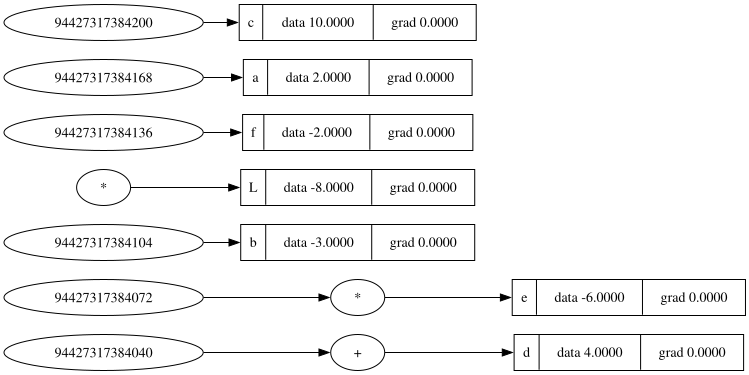

In [101]:
draw_digraph(L)

In [102]:
a.data += 0.01 * a._grad
b.data += 0.01 * b._grad
c.data += 0.01 * c._grad
f.data += 0.01 * f._grad

e = a * b
d = e + c
L = d * f

print(L.data)

-8.0


In [103]:
def lol():

  h = 0.001

  a = Value(2.0, _label='a')
  b = Value(-3.0, _label='b')
  c = Value(10.0, _label='c')
  e = a*b; e._label = 'e'
  d = e + c; d._label = 'd'
  f = Value(-2.0, _label='f')
  L = d * f; L._label = 'L'
  L1 = L.data

  a = Value(2.0, _label='a')
  b = Value(-3.0, _label='b')
  b.data += h
  c = Value(10.0, _label='c')
  e = a*b; e._label = 'e'
  d = e + c; d._label = 'd'
  f = Value(-2.0, _label='f')
  L = d * f; L._label = 'L'
  L2 = L.data

  print((L2 - L1)/h)

lol()

-3.9999999999995595


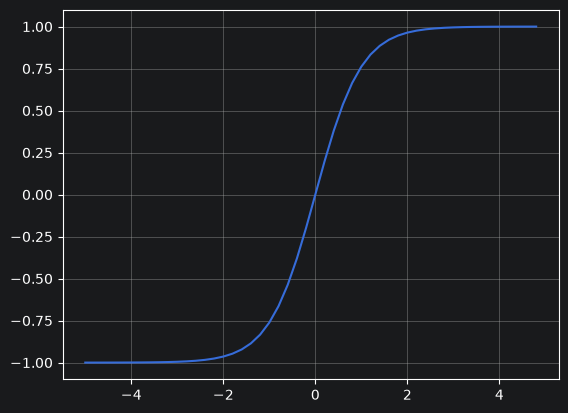

In [104]:
plt.plot(np.arange(-5,5,0.2), np.tanh(np.arange(-5,5,0.2))); plt.grid();

In [105]:
# inputs x1,x2
x1 = Value(2.0, _label='x1')
x2 = Value(0.0, _label='x2')
# weights w1,w2
w1 = Value(-3.0, _label='w1')
w2 = Value(1.0, _label='w2')
# bias of the neuron
b = Value(6.8813735870195432, _label='b')
# x1*w1 + x2*w2 + b
x1w1 = x1*w1; x1w1._label = 'x1*w1'
x2w2 = x2*w2; x2w2._label = 'x2*w2'
x1w1x2w2 = x1w1 + x2w2; x1w1x2w2._label = 'x1*w1 + x2*w2'
n = x1w1x2w2 + b; n._label = 'n'
o = n.tanh(); o._label = 'o'

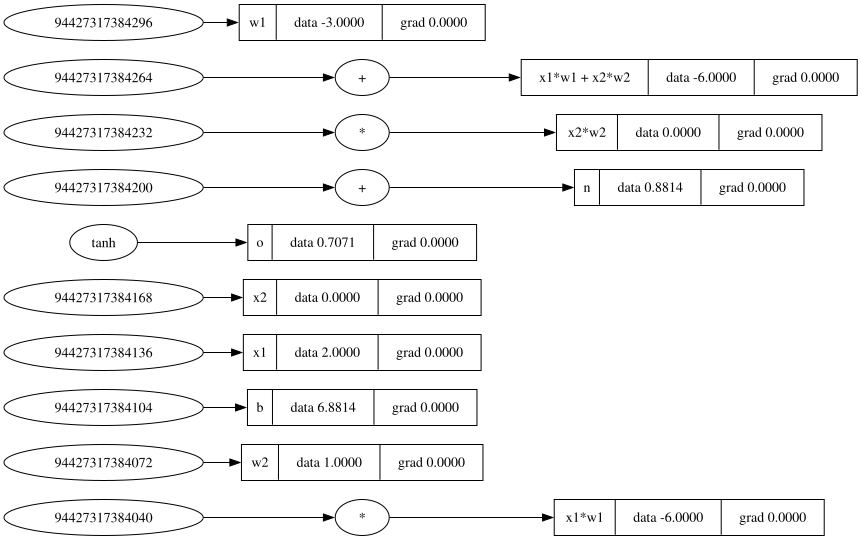

In [106]:
draw_digraph(o)

In [107]:
o.backward()

In [108]:
topo = []
visited = set()
def build_topo(v):
  if v not in visited:
    visited.add(v)
    for child in v._prev:
      build_topo(child)
    topo.append(v)
build_topo(o)
topo

[Value(data=6.881373587019543, label=b),
 Value(data=-3.0, label=w1),
 Value(data=2.0, label=x1),
 Value(data=-6.0, label=x1*w1),
 Value(data=1.0, label=w2),
 Value(data=0.0, label=x2),
 Value(data=0.0, label=x2*w2),
 Value(data=-6.0, label=x1*w1 + x2*w2),
 Value(data=0.8813735870195432, label=n),
 Value(data=0.7071067811865476, label=o)]

In [109]:
o.grad = 1.0

In [110]:
o._backward()

In [111]:
n._backward()
b._backward()

In [112]:
x1w1x2w2._backward()

In [115]:
x2w2._backward()
x1w1._backward()

x1._grad = w1.data * x1w1._grad
w1._grad = x1.data * x1w1._grad

x2._grad = w2.data * x2w2._grad
w2._grad = x2.data * x2w2._grad

x1w1._grad = 0.5
x2w2._grad = 0.5

x1w1x2w2._grad = 0.5
b._grad = 0.5

n._grad = 0.5

o._grad = 1.0

1 - o.data**2



0.4999999999999999

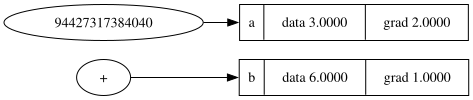

In [117]:
a = Value(3.0, _label='a')
b = a + a   ; b._label = 'b'
b.backward()
draw_digraph(b)
